In [197]:
import pandas as pd   ## search the package "pandans"
import statsmodels.api as sm    ## search the package "statsmodels"
import statsmodels.stats.api as sms   ## no need to install package
from statsmodels.compat import lzip   ## no need to install package
import matplotlib.pyplot as plt    ## search the package "matplotlib"
import seaborn as sns     ## search the package "seaborn"
import scipy.stats as scipy    ## search the package "scipy"
from scipy.stats import shapiro   ## no need to install package
import sys   ## no need to install package
import os   ## no need to install package

In [157]:
os.chdir('/Users/danieloheb/Desktop/CIS 9660')
##Change the address to your working folder

my_data = pd.read_csv("/Users/danieloheb/Desktop/CIS 9660/Cleaned_Crashes_Time_Categorized.csv", low_memory=False)

In [158]:
print(my_data)

       UNIQUE_ID  COLLISION_ID CRASH_DATE CRASH_TIME VEHICLE_ID  \
0       16940040       3410245   4/2/2016      15:00      83506   
1       16946320       3410974  3/26/2016      17:00      45898   
2       16949853       3415591  3/31/2016      13:00      69283   
3       16978228       3416164  4/19/2016      13:00     163503   
4       16939331       3416658  3/19/2016      18:20      17089   
...          ...           ...        ...        ...        ...   
39788   17311768       3518719  9/11/2016      20:30     778066   
39789   17414543       3578653  12/6/2016       3:00    1189706   
39790   17414544       3578653  12/6/2016       3:00    1189705   
39791   17414542       3578653  12/6/2016       3:00    1189702   
39792   17418022       3577117  12/9/2016      15:35    1187388   

      STATE_REGISTRATION                         VEHICLE_TYPE   VEHICLE_MAKE  \
0                     NY                           4 dr sedan  NISS -CAR/SUV   
1                     NY           

In [159]:
my_data.describe()

,UNIQUE_ID,COLLISION_ID,TRUCK,VEHICLE_YEAR,VEHICLE_AGE,VEHICLE_OCCUPANTS,NUMBER OF PERSONS INJURED,NUMBER OF PERSONS KILLED
count,3.979300e+04,3.979300e+04,39793.000000,39793.000000,39793.000000,39793.000000,39793.000000,39793.000000
mean,1.732001e+07,3.552416e+06,0.070641,2010.855452,15.144548,1.383510,0.326841,0.000754
std,8.837187e+04,3.809339e+04,0.256227,62.371048,62.371048,1.984562,0.780864,0.034723
min,1.668032e+07,3.407660e+06,0.000000,1958.000000,-7973.000000,0.000000,0.000000,0.000000
25%,1.727354e+07,3.529730e+06,0.000000,2006.000000,11.000000,1.000000,0.000000,0.000000
50%,1.733580e+07,3.550818e+06,0.000000,2012.000000,14.000000,1.000000,0.000000,0.000000
75%,1.738420e+07,3.571667e+06,0.000000,2015.000000,20.000000,2.000000,0.000000,0.000000
max,1.978721e+07,4.322963e+06,1.000000,9999.000000,68.000000,327.000000,12.000000,3.000000


In [160]:
# Data Cleaning

import pandas as pd

# Load the dataset
df = pd.read_csv("Motor_Vehicle_Collisions_-_Crashes.csv", low_memory=False)
original_len = len(df)

# 1. Clean data by dropping all rows with missing values
df_clean = df.dropna()
cleaned_len = len(df_clean)

print(f"Original rows: {original_len}")
print(f"Rows after complete dropna(): {cleaned_len}")

# Since the result might be 0 due to mostly-empty columns like 'VEHICLE_MODEL', 
# let's drop those entirely empty columns first, THEN dropna to give a usable dataset.
cols_to_drop = [col for col in df.columns if df[col].isnull().mean() > 0.5]
df_practical = df.drop(columns=cols_to_drop).dropna()
practical_len = len(df_practical)

print(f"\nColumns dropped due to >50% missing: {cols_to_drop}")
print(f"Rows after dropping empty columns and then dropna(): {practical_len}")

# We will apply the time categorization to the practically cleaned dataset
def categorize_time(time_str):
    try:
        hour = int(time_str.split(':')[0])
        if 6 <= hour < 12:
            return 'Morning'
        elif 12 <= hour < 16:
            return 'Afternoon'
        elif 16 <= hour < 19:
            return 'Peak Hours'
        else:
            return 'Night'
    except:
        return 'Unknown'

df_practical['Crash_Time_Occur'] = df_practical['CRASH_TIME'].apply(categorize_time)

print("\nDistribution of Crash_Time_Occur:")
print(df_practical['Crash_Time_Occur'].value_counts())

# Save to a new CSV
output_filename = "Cleaned_Crashes_Time_Categorized.csv"
df_practical.to_csv(output_filename, index=False)
print(f"\nSaved practical cleaned dataset to {output_filename}")

Original rows: 89102
Rows after complete dropna(): 0

Columns dropped due to >50% missing: ['VEHICLE_MODEL', 'VEHICLE_DAMAGE_2', 'VEHICLE_DAMAGE_3', 'PUBLIC_PROPERTY_DAMAGE_TYPE']
Rows after dropping empty columns and then dropna(): 39793

Distribution of Crash_Time_Occur:
Crash_Time_Occur
Night         11580
Morning       10573
Afternoon      9302
Peak Hours     8338
Name: count, dtype: int64

Saved practical cleaned dataset to Cleaned_Crashes_Time_Categorized.csv


In [161]:
file = open('project.txt','wt')
sys.stdout = file

In [162]:
df = pd.DataFrame(my_data)

In [163]:
import pandas as pd
import statsmodels.api as sm

# 1. Set your variables (y is what you predict, x is what causes it)
y = df['NUMBER OF PERSONS KILLED']

# 2. Convert the text column into numeric 'dummy' variables
# drop_first=True prevents the dummy variable trap (multicollinearity)
# dtype=int forces them to be 0s and 1s instead of True/False
x = pd.get_dummies(df['CONTRIBUTING_FACTOR_1'], drop_first=True, dtype=int)

# 3. Add the constant and run the model
x = sm.add_constant(x)

# 4. Fit the model and print
model1 = sm.OLS(y, x).fit(cov_type='HC0')

results_model1 = model1.summary()
print(results_model1)

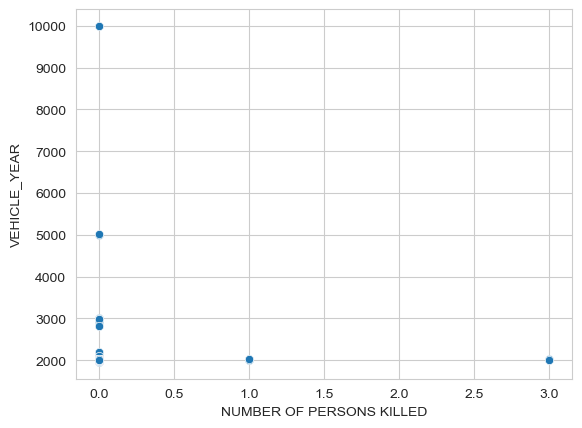

In [164]:
df["predicted1"] = model1.predict(x)

sns.scatterplot(data=df, x="NUMBER OF PERSONS KILLED", y="VEHICLE_YEAR")
plt.show()

In [201]:
import pandas as pd
import statsmodels.api as sm

# 1. Load data
df = pd.read_csv('Cleaned_Crashes_Time_Categorized.csv')
df = df.dropna(subset=['NUMBER OF PERSONS KILLED'])
df['IS_KILLED'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# 2. Find the Top 5 Deadliest Factors across BOTH columns
# 'Melt' the data to stack Factor 1 and Factor 2 on top of each other
melted = df.melt(id_vars=['UNIQUE_ID', 'NUMBER OF PERSONS KILLED'], 
                 value_vars=['CONTRIBUTING_FACTOR_1', 'CONTRIBUTING_FACTOR_2'],
                 value_name='FACTOR')

melted = melted.dropna(subset=['FACTOR'])
melted = melted[melted['FACTOR'] != 'Unspecified']

# Drop duplicates in case the same factor is listed in both columns for a single crash
melted = melted.drop_duplicates(subset=['UNIQUE_ID', 'FACTOR'])

# Sum deaths per factor
deadly_factors = melted.groupby('FACTOR')['NUMBER OF PERSONS KILLED'].sum().sort_values(ascending=False).head(5).index.tolist()

# 3. Prepare Data for Modeling
# Create a 1 or 0 column for each of the top 5 factors if it appears in EITHER Factor 1 or Factor 2
for factor in deadly_factors:
    df[factor] = ((df['CONTRIBUTING_FACTOR_1'] == factor) | (df['CONTRIBUTING_FACTOR_2'] == factor)).astype(int)

# Filter out crashes where EVERYTHING is 'Unspecified' or NaN, so our baseline is fair
known_crashes = df[(df['CONTRIBUTING_FACTOR_1'].notna() & (df['CONTRIBUTING_FACTOR_1'] != 'Unspecified')) | 
                   (df['CONTRIBUTING_FACTOR_2'].notna() & (df['CONTRIBUTING_FACTOR_2'] != 'Unspecified'))].copy()

# 4. Run Logistic Regression
y_logit = known_crashes['IS_KILLED']
X_logit = known_crashes[deadly_factors]
X_logit = sm.add_constant(X_logit)

logit_model = sm.Logit(y_logit, X_logit).fit()
print("=== LOGISTIC REGRESSION (Considering Both Factors) ===")
print(logit_model.summary())

In [166]:
import pandas as pd
import statsmodels.api as sm

print("1. Starting script...")

# 1. Load data
print("2. Loading dataset... (This might take a minute if the file is large)")
df = pd.read_csv('Cleaned_Crashes_Time_Categorized.csv', low_memory=False)
df = df.dropna(subset=['NUMBER OF PERSONS KILLED'])
df['IS_KILLED'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)








In [167]:
# 2. Find the Top 5 Deadliest Factors
print("3. Melting data to find top factors... (This can be slow on large datasets)")
melted = df.melt(id_vars=['UNIQUE_ID', 'NUMBER OF PERSONS KILLED'], 
                 value_vars=['CONTRIBUTING_FACTOR_1', 'CONTRIBUTING_FACTOR_2'],
                 value_name='FACTOR')

melted = melted.dropna(subset=['FACTOR'])
melted = melted[melted['FACTOR'] != 'Unspecified']
melted = melted.drop_duplicates(subset=['UNIQUE_ID', 'FACTOR'])

deadly_factors = melted.groupby('FACTOR')['NUMBER OF PERSONS KILLED'].sum().sort_values(ascending=False).head(20).index.tolist()
print(f"   -> Successfully found factors: {deadly_factors}")


In [168]:
# 3. Prepare Data for Modeling
print("4. Creating binary columns for the regression...")
for factor in deadly_factors:
    df[factor] = ((df['CONTRIBUTING_FACTOR_1'] == factor) | (df['CONTRIBUTING_FACTOR_2'] == factor)).astype(int)

print("5. Filtering crashes to establish the baseline...")
known_crashes = df[(df['CONTRIBUTING_FACTOR_1'].notna() & (df['CONTRIBUTING_FACTOR_1'] != 'Unspecified')) | 
                   (df['CONTRIBUTING_FACTOR_2'].notna() & (df['CONTRIBUTING_FACTOR_2'] != 'Unspecified'))].copy()

In [169]:
# 4. Run Logistic Regression
print("6. Preparing data for the math engine...")
y_logit = known_crashes['IS_KILLED']
X_logit = known_crashes[deadly_factors]
X_logit = sm.add_constant(X_logit)

print("7. Fitting the model... (Waiting for convergence...)")
try:
    # disp=True forces statsmodels to print its iterations so you know it's not frozen
    logit_model = sm.Logit(y_logit, X_logit).fit(disp=True) 
    print("\n=== LOGISTIC REGRESSION (Considering Both Factors) ===")
    print(logit_model.summary())
except Exception as e:
    print("\n!!! ERROR FITTING MODEL !!!")
    print(f"The error is: {e}")

print("8. Script finished.")

In [170]:
import pandas as pd
import statsmodels.api as sm

# 1. Load Data and Clean the Vehicle Makes
df = pd.read_csv('Cleaned_Crashes_Time_Categorized.csv', low_memory=False)

# Extract the first word of the vehicle make (which contains the 4-letter brand code)
df['CLEAN_MAKE'] = df['VEHICLE_MAKE'].astype(str).str.upper().str.split().str[0]

# Filter to the top 5 most common brands to ensure we have enough data
top_brands = ['TOYT', 'HOND', 'NISS', 'FORD', 'CHEV']
df_cars = df[df['CLEAN_MAKE'].isin(top_brands)].copy()

# Create target variable: 1 if someone was killed, 0 otherwise
df_cars['IS_KILLED'] = (df_cars['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# 2. Print Raw Death Rates
print("Crash and Death Counts by Brand:")
summary = df_cars.groupby('CLEAN_MAKE')['IS_KILLED'].agg(['count', 'sum']).rename(columns={'count': 'Total Crashes', 'sum': 'Fatal Crashes'})
summary['Fatal Crashes per 10k'] = (summary['Fatal Crashes'] / summary['Total Crashes']) * 10000
print(summary.sort_values(by='Fatal Crashes per 10k', ascending=False))

# 3. Run Logistic Regression (Using Toyota as the Baseline)
X_makes = pd.get_dummies(df_cars['CLEAN_MAKE'], drop_first=False, dtype=int)
X_makes = X_makes.drop(columns=['FORD']) # Drop Toyota to make it the baseline
X_makes = sm.add_constant(X_makes)

y_logit = df_cars['IS_KILLED']

logit_model = sm.Logit(y_logit, X_makes).fit(disp=False)
print("\n=== LOGISTIC REGRESSION: Brand vs Mortality (Baseline = TOYOTA) ===")
print(logit_model.summary())

In [171]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

# Load data
df = pd.read_csv("Motor_Vehicle_Collisions_-_Crashes.csv", low_memory=False)

# Target: FATAL
df['FATAL'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# Predictor 1: Brand (Focus on FORD vs OTHERS for simplicity, or keep top 5)
def get_brand(make):
    make = str(make).upper().strip()
    if 'FORD' in make: return 'FORD'
    if 'TOYT' in make or 'TOYOTA' in make: return 'TOYOTA'
    if 'HOND' in make: return 'HONDA'
    if 'NISS' in make: return 'NISSAN'
    if 'CHEV' in make: return 'CHEVROLET'
    return 'OTHER'
df['BRAND'] = df['VEHICLE_MAKE'].apply(get_brand)

# Predictor 2: Time of Day
df['CRASH_TIME'] = pd.to_datetime(df['CRASH_TIME'], format='%H:%M', errors='coerce')
df['HOUR'] = df['CRASH_TIME'].dt.hour
def time_of_day(h):
    if pd.isna(h): return 'UNKNOWN'
    if 6 <= h < 18: return 'DAY'
    return 'NIGHT'
df['TIME_OF_DAY'] = df['HOUR'].apply(time_of_day)

# Predictor 3: Vehicle Type
def get_veh_type(vt):
    vt = str(vt).upper()
    if 'SEDAN' in vt or '4 DR' in vt or '2 DR' in vt or 'PASSENGER' in vt: return 'SEDAN'
    if 'SUV' in vt or 'SPORT UTILITY' in vt: return 'SUV'
    if 'TRUCK' in vt or 'BUS' in vt or 'VAN' in vt: return 'HEAVY'
    return 'OTHER_TYPE'
df['VEHICLE_TYPE_CLEAN'] = df['VEHICLE_TYPE'].apply(get_veh_type)

# Predictor 4: Cause
def group_factor(factor):
    factor = str(factor).upper()
    if 'DISTRACTION' in factor or 'INATTENTION' in factor: return 'DISTRACTION'
    if 'SPEED' in factor: return 'SPEED'
    if 'ALCOHOL' in factor or 'DRUG' in factor: return 'SUBSTANCE'
    if 'YIELD' in factor or 'TRAFFIC CONTROL' in factor or 'STOP' in factor: return 'TRAFFIC_VIOLATION'
    if 'UNSPECIFIED' in factor: return 'UNSPECIFIED'
    return 'OTHER_CAUSE'
df['CAUSE'] = df['CONTRIBUTING_FACTOR_1'].apply(group_factor)

# Build Model Data
model_cols = ['FATAL', 'BRAND', 'TIME_OF_DAY', 'VEHICLE_TYPE_CLEAN', 'CAUSE']
df_model = df[model_cols].copy()

# Filter out UNKNOWN time
df_model = df_model[df_model['TIME_OF_DAY'] != 'UNKNOWN']

# We want to see if FORD specifically is a driver compared to the baseline (OTHER)
# Create dummies. drop_first=True makes alphabetical first the baseline.
# Let's explicitly define dummies to ensure 'OTHER' is baseline.
brand_dummies = pd.get_dummies(df_model['BRAND'], prefix='BRAND').drop('BRAND_OTHER', axis=1)
time_dummies = pd.get_dummies(df_model['TIME_OF_DAY'], prefix='TIME').drop('TIME_DAY', axis=1) # DAY is baseline
type_dummies = pd.get_dummies(df_model['VEHICLE_TYPE_CLEAN'], prefix='TYPE').drop('TYPE_OTHER_TYPE', axis=1) # OTHER is baseline
cause_dummies = pd.get_dummies(df_model['CAUSE'], prefix='CAUSE').drop('CAUSE_UNSPECIFIED', axis=1) # UNSPECIFIED is baseline

X = pd.concat([brand_dummies, time_dummies, type_dummies, cause_dummies], axis=1)
# Convert all to float
X = X.astype(float)
X = sm.add_constant(X)
y = df_model['FATAL'].astype(float)

print("Starting regression...")
try:
    logit_model = sm.Logit(y, X).fit(maxiter=50)
    print(logit_model.summary())
except Exception as e:
    print("Regression failed:", e)
    
# Calculate basic cross-tab for Ford fatalities vs non-Ford
print("\nFatality Rate by Brand:")
print(df_model.groupby('BRAND')['FATAL'].mean() * 100)

# Let's check X sums to find sparse columns causing singular matrix or perfect separation
print(X.sum())

# We can see NISSAN has 0 fatalities from earlier, which causes perfect separation (Logit fails if a dummy perfectly predicts 0).
# Let's drop NISSAN from the model or use a regularized fit.
X_clean = X.drop('BRAND_NISSAN', axis=1)

# Let's try again
try:
    logit_model = sm.Logit(y, X_clean).fit(disp=0)
    print(logit_model.summary())
except Exception as e:
    # Fallback to regularized
    logit_model = sm.Logit(y, X_clean).fit_regularized(disp=0)
    print(logit_model.summary())

In [172]:
# Let's check X sums to find sparse columns causing singular matrix or perfect separation
print(X.sum())

# We can see NISSAN has 0 fatalities from earlier, which causes perfect separation (Logit fails if a dummy perfectly predicts 0).
# Let's drop NISSAN from the model or use a regularized fit.
X_clean = X.drop('BRAND_NISSAN', axis=1)

# Let's try again
try:
    logit_model = sm.Logit(y, X_clean).fit(disp=0)
    print(logit_model.summary())
except Exception as e:
    # Fallback to regularized
    logit_model = sm.Logit(y, X_clean).fit_regularized(disp=0)
    print(logit_model.summary())

In [173]:
# Write up 3 work:

# statmodels:

# Print the summary statistics for the Independent Variables (Predictors / X)
# We use X_clean since we dropped the NISSAN variable to avoid perfect separation
print("--- Summary Statistics for Predictor Variables (X) ---")
display(X_clean.describe().round(4))

# Print the summary statistics for the Dependent Variable (Target / Y)
print("\n--- Summary Statistics for Target Variable (Y: FATAL) ---")
display(y.describe().round(4))

,const,BRAND_CHEVROLET,BRAND_FORD,BRAND_HONDA,BRAND_TOYOTA,TIME_NIGHT,TYPE_HEAVY,TYPE_SEDAN,TYPE_SUV,CAUSE_DISTRACTION,CAUSE_OTHER_CAUSE,CAUSE_SPEED,CAUSE_SUBSTANCE,CAUSE_TRAFFIC_VIOLATION
count,89102.0,89102.0000,89102.000,89102.0000,89102.0000,89102.0000,89102.0000,89102.0000,89102.0000,89102.0000,89102.0000,89102.0000,89102.0000,89102.0000
mean,1.0,0.0488,0.092,0.1052,0.1597,0.3497,0.0861,0.4628,0.2994,0.1531,0.2786,0.0099,0.0064,0.0485
std,0.0,0.2154,0.289,0.3068,0.3663,0.4769,0.2805,0.4986,0.4580,0.3601,0.4483,0.0991,0.0799,0.2148
min,1.0,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,1.0,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
50%,1.0,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
75%,1.0,0.0000,0.000,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000
max,1.0,1.0000,1.000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


count    89102.0000
mean         0.0006
std          0.0237
min          0.0000
25%          0.0000
50%          0.0000
75%          0.0000
max          1.0000
Name: FATAL, dtype: float64

In [174]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Load the dataset
df = pd.read_csv('/Users/danieloheb/Desktop/CIS 9660/Cleaned_Crashes_Time_Categorized.csv', low_memory=False)

# 2. Define the analytical numerical variables
num_cols = ['VEHICLE_OCCUPANTS', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'VEHICLE_YEAR']

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 3. Create a 2x2 grid so each variable gets its own independent Y-axis scale
fig = make_subplots(
    rows=2, cols=2, 
    subplot_titles=[
        "Vehicle Occupants", 
        "Number of Persons Injured", 
        "Number of Persons Killed", 
        "Vehicle Year"
    ]
)

# 4. Map each variable to a specific row and column
positions = [(1, 1), (1, 2), (2, 1), (2, 2)]

for i, col in enumerate(num_cols):
    row, col_pos = positions[i]
    fig.add_trace(
        go.Box(
            y=df[col].dropna(), 
            name=col, 
            boxpoints='outliers', # Only display outlier dots
            marker_color='rgb(8,81,156)'
        ), 
        row=row, col=col_pos
    )

# 5. Format and save
fig.update_layout(
    height=800, 
    width=1000,
    title_text="Outlier Detection Dashboard (Independent Scales)",
    showlegend=False,
    template='plotly_white'
)

fig.write_html("all_variables_outliers_subplots.html")

In [9]:
import pandas as pd
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

# Load data
df = pd.read_csv('/Users/danieloheb/Desktop/CIS 9660/Cleaned_Crashes_Time_Categorized.csv', low_memory=False)

# Target
df['FATAL'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# Predictor: FORD
df['FORD'] = df['VEHICLE_MAKE'].astype(str).str.upper().str.contains('FORD').astype(int)

# --- Model 1: Gender Hypothesis ---
df_m1 = df[['FATAL', 'FORD', 'DRIVER_SEX']].dropna()
df_m1 = df_m1[df_m1['DRIVER_SEX'].isin(['M', 'F'])]
df_m1['MALE'] = (df_m1['DRIVER_SEX'] == 'M').astype(int)

print("--- MODEL 1: GENDER ---")
try:
    m1 = smf.logit('FATAL ~ FORD + MALE', data=df_m1).fit(disp=0)
    print(m1.summary())
except Exception as e:
    print("Error:", e)


# --- Model 2: Time of Day Hypothesis ---

# 1. Convert to datetime and extract the hour
df['CRASH_TIME'] = pd.to_datetime(df['CRASH_TIME'], format='%H:%M', errors='coerce')
df['HOUR'] = df['CRASH_TIME'].dt.hour

# 2. Create mutually exclusive time bins covering 24 hours
df['MORNING'] = ((df['HOUR'] >= 6) & (df['HOUR'] < 12)).astype(int)   # 6 AM to 11:59 AM
df['AFTERNOON'] = ((df['HOUR'] >= 12) & (df['HOUR'] < 16)).astype(int) # 12 PM to 3:59 PM
df['PEAK'] = ((df['HOUR'] >= 16) & (df['HOUR'] < 20)).astype(int)      # 4 PM to 7:59 PM
df['NIGHT'] = ((df['HOUR'] >= 20) | (df['HOUR'] < 6)).astype(int)      # 8 PM to 5:59 AM

df_m2 = df[['FATAL', 'FORD', 'AFTERNOON', 'NIGHT']].dropna()

print("\n--- MODEL 2: TIME OF DAY ---")
try:
    # Testing both Afternoon and Night against the Morning baseline (6 AM - 11 AM)
    m2 = smf.logit('FATAL ~ FORD + AFTERNOON + NIGHT', data=df_m2).fit(disp=0)
    print(m2.summary())
except Exception as e:
    print("Error:", e)


# --- Model 3: Vehicle Type (Trucks/SUVs) Hypothesis ---
# User asked if "Truck" causes death. I will classify Trucks, Vans, and SUVs as "TRUCK" for this test.
df['TRUCK'] = df['VEHICLE_TYPE'].astype(str).str.upper().str.contains('TRUCK|SUV|VAN|UTILITY').astype(int)

df_m3 = df[['FATAL', 'FORD', 'TRUCK']].dropna()

print("\n--- MODEL 3: VEHICLE TYPE ---")
try:
    m3 = smf.logit('FATAL ~ FORD + TRUCK', data=df_m3).fit(disp=0)
    print(m3.summary())
except Exception as e:
    print("Error:", e)

--- MODEL 1: GENDER ---
                           Logit Regression Results                           
Dep. Variable:                  FATAL   No. Observations:                39713
Model:                          Logit   Df Residuals:                    39710
Method:                           MLE   Df Model:                            2
Date:                Wed, 06 May 2026   Pseudo R-squ.:                0.002965
Time:                        11:38:09   Log-Likelihood:                -201.27
converged:                       True   LL-Null:                       -201.87
Covariance Type:            nonrobust   LLR p-value:                    0.5497
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -7.5794      0.413    -18.340      0.000      -8.389      -6.769
FORD           0.6134      0.550      1.116      0.264      -0.464       1.691
MALE           0.1218      0

In [11]:
import pandas as pd
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

# Load data (Using the correct CSV file)
df = pd.read_csv("Cleaned_Crashes_Time_Categorized.csv", low_memory=False)

# Target
df['FATAL'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# Predictor: FORD
df['FORD'] = df['VEHICLE_MAKE'].astype(str).str.upper().str.contains('FORD').astype(int)

# --- Model 1: Gender Hypothesis ---
df_m1 = df[['FATAL', 'FORD', 'DRIVER_SEX']].dropna()
df_m1 = df_m1[df_m1['DRIVER_SEX'].isin(['M', 'F'])]
df_m1['MALE'] = (df_m1['DRIVER_SEX'] == 'M').astype(int)

print("--- MODEL 1: GENDER ---")
try:
    m1 = smf.logit('FATAL ~ FORD + MALE', data=df_m1).fit(disp=0)
    print(m1.summary())
except Exception as e:
    print("Error:", e)


# --- Model 2: Time of Day Hypothesis ---
# 1. Convert to datetime and extract the hour
df['CRASH_TIME'] = pd.to_datetime(df['CRASH_TIME'], format='%H:%M', errors='coerce')
df['HOUR'] = df['CRASH_TIME'].dt.hour

# 2. Create mutually exclusive time bins covering 24 hours
df['MORNING'] = ((df['HOUR'] >= 6) & (df['HOUR'] < 12)).astype(int)   # 6 AM to 11:59 AM
df['AFTERNOON'] = ((df['HOUR'] >= 12) & (df['HOUR'] < 16)).astype(int) # 12 PM to 3:59 PM
df['PEAK'] = ((df['HOUR'] >= 16) & (df['HOUR'] < 20)).astype(int)      # 4 PM to 7:59 PM
df['NIGHT'] = ((df['HOUR'] >= 20) | (df['HOUR'] < 6)).astype(int)      # 8 PM to 5:59 AM

df_m2 = df[['FATAL', 'FORD', 'AFTERNOON', 'NIGHT']].dropna()

print("\n--- MODEL 2: TIME OF DAY ---")
try:
    # Testing both Afternoon and Night against the Morning baseline (6 AM - 11 AM)
    m2 = smf.logit('FATAL ~ FORD + AFTERNOON + NIGHT', data=df_m2).fit(disp=0)
    print(m2.summary())
except Exception as e:
    print("Error:", e)


# --- Model 3: Vehicle Type (Trucks/SUVs) Hypothesis ---
# User asked if "Truck" causes death. I will classify Trucks, Vans, and SUVs as "TRUCK" for this test.
df['TRUCK'] = df['VEHICLE_TYPE'].astype(str).str.upper().str.contains('TRUCK|SUV|VAN|UTILITY').astype(int)

df_m3 = df[['FATAL', 'FORD', 'TRUCK']].dropna()

print("\n--- MODEL 3: VEHICLE TYPE ---")
try:
    m3 = smf.logit('FATAL ~ FORD + TRUCK', data=df_m3).fit(disp=0)
    print(m3.summary())
except Exception as e:
    print("Error:", e)


# --- Model 4: Seasonality Hypothesis ---
print("\n--- MODEL 4: SEASONALITY (Baseline = FALL) ---")

# 1. Convert CRASH_DATE to datetime and extract the month
df['CRASH_DATE'] = pd.to_datetime(df['CRASH_DATE'], errors='coerce')
df['MONTH'] = df['CRASH_DATE'].dt.month

# 2. Create mutually exclusive season bins based on standard meteorological seasons
df['WINTER'] = df['MONTH'].isin([12, 1, 2]).astype(int)
df['SPRING'] = df['MONTH'].isin([3, 4, 5]).astype(int)
df['SUMMER'] = df['MONTH'].isin([6, 7, 8]).astype(int)
df['FALL'] = df['MONTH'].isin([9, 10, 11]).astype(int)

# 3. Prepare DataFrame, dropping missing rows
df_m4 = df[['FATAL', 'FORD', 'WINTER', 'SPRING', 'SUMMER', 'FALL']].dropna()

try:
    # We must leave one out to act as the baseline. 
    # NOTE: In this specific dataset, Fall has the most data, making it the safest baseline.
    m4 = smf.logit('FATAL ~ FORD + SPRING + SUMMER + WINTER', data=df_m4).fit(disp=0)
    print(m4.summary())
except Exception as e:
    print("Error:", e)

--- MODEL 1: GENDER ---
                           Logit Regression Results                           
Dep. Variable:                  FATAL   No. Observations:                39713
Model:                          Logit   Df Residuals:                    39710
Method:                           MLE   Df Model:                            2
Date:                Wed, 06 May 2026   Pseudo R-squ.:                0.002965
Time:                        11:38:17   Log-Likelihood:                -201.27
converged:                       True   LL-Null:                       -201.87
Covariance Type:            nonrobust   LLR p-value:                    0.5497
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -7.5794      0.413    -18.340      0.000      -8.389      -6.769
FORD           0.6134      0.550      1.116      0.264      -0.464       1.691
MALE           0.1218      0

In [3]:
df = pd.read_csv('/Users/danieloheb/Desktop/CIS 9660/Cleaned_Crashes_Time_Categorized.csv', low_memory=False)

In [19]:
# --- Quick Outlier Filter ---
# 1. Keep only realistic vehicle years (e.g., cars made between 1900 and 2026)
df = df[(df['VEHICLE_YEAR'] >= 1900) & (df['VEHICLE_YEAR'] <= 2026)]

# 2. Keep only realistic vehicle occupancy (e.g., standard vehicles/buses under 100)
df = df[df['VEHICLE_OCCUPANTS'] < 100]

# Now, recalculate VEHICLE_AGE to ensure no negative numbers remain
df['VEHICLE_AGE'] = 2026 - df['VEHICLE_YEAR']

In [27]:
import pandas as pd
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

# 2. Target Variable
df['FATAL'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# 3. Predictor 1: FORD (Baseline = Not Ford)
df['FORD'] = df['VEHICLE_MAKE'].astype(str).str.upper().str.contains('FORD').astype(int)

# 4. Predictor 2: Gender (Baseline = Female)
df = df[df['DRIVER_SEX'].isin(['M', 'F'])]
df['MALE'] = (df['DRIVER_SEX'] == 'M').astype(int)

# 5. Predictor 3: Vehicle Age
df['VEHICLE_AGE'] = pd.to_numeric(df['VEHICLE_AGE'], errors='coerce')

# 7. Predictor 5: Time of Day (Baseline = Morning)
df['CRASH_TIME'] = pd.to_datetime(df['CRASH_TIME'], format='%H:%M', errors='coerce')
df['HOUR'] = df['CRASH_TIME'].dt.hour
df['MORNING'] = ((df['HOUR'] >= 6) & (df['HOUR'] < 12)).astype(int)
df['AFTERNOON'] = ((df['HOUR'] >= 12) & (df['HOUR'] < 16)).astype(int)
df['PEAK'] = ((df['HOUR'] >= 16) & (df['HOUR'] < 20)).astype(int)
df['NIGHT'] = ((df['HOUR'] >= 20) | (df['HOUR'] < 6)).astype(int)

# 8. Predictor 6: Season (Baseline = Fall)
df['CRASH_DATE'] = pd.to_datetime(df['CRASH_DATE'], errors='coerce')
df['MONTH'] = df['CRASH_DATE'].dt.month
df['WINTER'] = df['MONTH'].isin([12, 1, 2]).astype(int)
df['SPRING'] = df['MONTH'].isin([3, 4, 5]).astype(int)
df['SUMMER'] = df['MONTH'].isin([6, 7, 8]).astype(int)
df['FALL'] = df['MONTH'].isin([9, 10, 11]).astype(int)

# 9. Clean Data & Drop NAs for Model Columns
model_cols = [
    'FATAL', 'FORD', 'MALE', 'VEHICLE_AGE', 
    'AFTERNOON', 'PEAK', 'NIGHT',
    'SPRING', 'SUMMER', 'WINTER'
]
df_model = df[model_cols].dropna()

# 10. Run the Master Unified Logit Model
print("\n--- LOGIT MODEL ---")
try:
    formula = "FATAL ~ FORD + MALE + VEHICLE_AGE + AFTERNOON + PEAK + NIGHT + SPRING + SUMMER + WINTER"
    m_master = smf.logit(formula, data=df_model).fit(disp=0)
    print(m_master.summary())
except Exception as e:
    print("Error:", e)


--- LOGIT MODEL ---
                           Logit Regression Results                           
Dep. Variable:                  FATAL   No. Observations:                39689
Model:                          Logit   Df Residuals:                    39679
Method:                           MLE   Df Model:                            9
Date:                Wed, 06 May 2026   Pseudo R-squ.:                 0.03507
Time:                        12:33:21   Log-Likelihood:                -194.77
converged:                      False   LL-Null:                       -201.85
Covariance Type:            nonrobust   LLR p-value:                    0.1168
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -8.4149      0.818    -10.290      0.000     -10.018      -6.812
FORD            0.6850      0.551      1.244      0.214      -0.394       1.764
MALE            0.0041     

In [180]:
pd.set_option('display.max_columns', None)

In [209]:
df.describe()

,UNIQUE_ID,COLLISION_ID,CRASH_DATE,CRASH_TIME,TRUCK,VEHICLE_YEAR,VEHICLE_AGE,VEHICLE_OCCUPANTS,NUMBER OF PERSONS INJURED,NUMBER OF PERSONS KILLED,...,HOUR,MORNING,AFTERNOON,PEAK,NIGHT,MONTH,WINTER,SPRING,SUMMER,FALL
count,3.968900e+04,3.968900e+04,39689,39689,39689.000000,39689.000000,39689.000000,39689.000000,39689.000000,39689.000000,...,39689.000000,39689.000000,39689.000000,39689.000000,39689.000000,39689.000000,39689.000000,39689.000000,39689.000000,39689.000000
mean,1.732000e+07,3.552411e+06,2016-10-31 01:48:31.184459008,1900-01-01 13:29:04.471768064,0.070473,2010.064829,15.935171,1.375444,0.326589,0.000756,...,13.088286,0.265792,0.233642,0.258082,0.242485,10.190431,0.242511,0.005216,0.065812,0.686462
min,1.668032e+07,3.407660e+06,2016-03-19 00:00:00,1900-01-01 00:00:00,0.000000,1958.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.727353e+07,3.529726e+06,2016-09-28 00:00:00,1900-01-01 09:30:00,0.000000,2006.000000,11.000000,1.000000,0.000000,0.000000,...,9.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,0.000000,0.000000,0.000000
50%,1.733572e+07,3.550819e+06,2016-10-29 00:00:00,1900-01-01 14:13:00,0.000000,2012.000000,14.000000,1.000000,0.000000,0.000000,...,14.000000,0.000000,0.000000,0.000000,0.000000,10.000000,0.000000,0.000000,0.000000,1.000000
75%,1.738421e+07,3.571646e+06,2016-11-30 00:00:00,1900-01-01 17:52:00,0.000000,2015.000000,20.000000,2.000000,0.000000,0.000000,...,17.000000,1.000000,0.000000,1.000000,0.000000,11.000000,0.000000,0.000000,0.000000,1.000000
max,1.978721e+07,4.322963e+06,2018-11-15 00:00:00,1900-01-01 23:59:00,1.000000,2026.000000,68.000000,62.000000,12.000000,3.000000,...,23.000000,1.000000,1.000000,1.000000,1.000000,12.000000,1.000000,1.000000,1.000000,1.000000
std,8.836528e+04,3.809221e+04,NaN,NaN,0.255946,5.502922,5.502922,1.129095,0.779880,0.034769,...,5.821192,0.441759,0.423152,0.437585,0.428592,1.703645,0.428607,0.072031,0.247956,0.463937


In [182]:
# to reset this
pd.reset_option('display.max_columns')

In [183]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import plotly.express as px
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')

# 1. Load Data
df = pd.read_csv("Cleaned_Crashes_Time_Categorized.csv", low_memory=False)

# 2. Prep Variables (Same as Master Model)
df['FATAL'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)
df['FORD'] = df['VEHICLE_MAKE'].astype(str).str.upper().str.contains('FORD').astype(int)

df = df[df['DRIVER_SEX'].isin(['M', 'F'])]
df['MALE'] = (df['DRIVER_SEX'] == 'M').astype(int)
df['VEHICLE_AGE'] = pd.to_numeric(df['VEHICLE_AGE'], errors='coerce')

def get_veh_type(vt):
    vt = str(vt).upper()
    if 'SEDAN' in vt or '4 DR' in vt or '2 DR' in vt or 'PASSENGER' in vt: return 'SEDAN'
    if 'SUV' in vt or 'SPORT UTILITY' in vt: return 'SUV'
    if 'TRUCK' in vt or 'BUS' in vt or 'VAN' in vt or 'UTILITY' in vt: return 'TRUCK'
    return 'OTHER_TYPE'
df['VEHICLE_TYPE_CLEAN'] = df['VEHICLE_TYPE'].apply(get_veh_type)
df['TYPE_TRUCK'] = (df['VEHICLE_TYPE_CLEAN'] == 'TRUCK').astype(int)
df['TYPE_SUV'] = (df['VEHICLE_TYPE_CLEAN'] == 'SUV').astype(int)
df['TYPE_SEDAN'] = (df['VEHICLE_TYPE_CLEAN'] == 'SEDAN').astype(int)

df['CRASH_TIME'] = pd.to_datetime(df['CRASH_TIME'], format='%H:%M', errors='coerce')
df['HOUR'] = df['CRASH_TIME'].dt.hour
df['MORNING'] = ((df['HOUR'] >= 6) & (df['HOUR'] < 12)).astype(int)
df['AFTERNOON'] = ((df['HOUR'] >= 12) & (df['HOUR'] < 16)).astype(int)
df['PEAK'] = ((df['HOUR'] >= 16) & (df['HOUR'] < 20)).astype(int)
df['NIGHT'] = ((df['HOUR'] >= 20) | (df['HOUR'] < 6)).astype(int)

def get_time_label(row):
    if row['MORNING']: return 'Morning'
    if row['AFTERNOON']: return 'Afternoon'
    if row['PEAK']: return 'Peak'
    if row['NIGHT']: return 'Night'
    return 'Unknown'
df['TIME_LABEL'] = df.apply(get_time_label, axis=1)

df['CRASH_DATE'] = pd.to_datetime(df['CRASH_DATE'], errors='coerce')
df['MONTH'] = df['CRASH_DATE'].dt.month
df['WINTER'] = df['MONTH'].isin([12, 1, 2]).astype(int)
df['SPRING'] = df['MONTH'].isin([3, 4, 5]).astype(int)
df['SUMMER'] = df['MONTH'].isin([6, 7, 8]).astype(int)
df['FALL'] = df['MONTH'].isin([9, 10, 11]).astype(int)

# 3. Add Cause for visualizations (even if not in logit)
def group_factor(factor):
    factor = str(factor).upper()
    if 'DISTRACTION' in factor or 'INATTENTION' in factor: return 'DISTRACTION'
    if 'SPEED' in factor: return 'SPEED'
    if 'ALCOHOL' in factor or 'DRUG' in factor: return 'SUBSTANCE'
    if 'YIELD' in factor or 'TRAFFIC CONTROL' in factor or 'STOP' in factor: return 'TRAFFIC_VIOLATION'
    if 'UNSPECIFIED' in factor: return 'UNSPECIFIED'
    return 'OTHER_CAUSE'
df['CAUSE'] = df['CONTRIBUTING_FACTOR_1'].apply(group_factor)

# Apply Outlier Filter so age is realistic
df = df[(df['VEHICLE_YEAR'] >= 1900) & (df['VEHICLE_YEAR'] <= 2026)]
df = df[df['VEHICLE_OCCUPANTS'] < 100]
df['VEHICLE_AGE'] = 2026 - df['VEHICLE_YEAR']

model_cols = [
    'FATAL', 'FORD', 'MALE', 'VEHICLE_AGE', 
    'TYPE_TRUCK', 'TYPE_SUV', 'TYPE_SEDAN',
    'AFTERNOON', 'PEAK', 'NIGHT',
    'SPRING', 'SUMMER', 'WINTER'
]
df_model = df[model_cols].dropna()

# --- PLOT 1: Forest Plot of Coefficients ---
formula = "FATAL ~ FORD + MALE + VEHICLE_AGE + TYPE_TRUCK + TYPE_SUV + TYPE_SEDAN + AFTERNOON + PEAK + NIGHT + SPRING + SUMMER + WINTER"
m_master = smf.logit(formula, data=df_model).fit(disp=0)

# Extract conf intervals and coefficients
ci = m_master.conf_int()
ci.columns = ['Lower', 'Upper']
ci['Coef'] = m_master.params
ci['P_Value'] = m_master.pvalues
ci = ci.drop('Intercept') # Drop intercept for scale reasons

# Sort by coefficient
ci = ci.sort_values(by='Coef')

fig1 = go.Figure()
fig1.add_trace(go.Scatter(
    x=ci['Coef'],
    y=ci.index,
    mode='markers',
    marker=dict(
        color=['red' if p > 0.05 else 'blue' for p in ci['P_Value']],
        size=10
    ),
    error_x=dict(
        type='data',
        symmetric=False,
        array=ci['Upper'] - ci['Coef'],
        arrayminus=ci['Coef'] - ci['Lower'],
        color='gray'
    ),
    name='Log-Odds'
))

fig1.add_vline(x=0, line_dash="dash", line_color="black")
fig1.update_layout(
    title="Logit Model Coefficients (Forest Plot)<br><sup>Blue = Significant (p < 0.05) | Red = Insignificant | Whisker = 95% Confidence Interval</sup>",
    xaxis_title="Impact on Log-Odds of Fatality",
    yaxis_title="Predictor Variable",
    template="plotly_white",
    height=600
)
fig1.show


# --- PLOT 2: Heatmap of Fatality Rate by Time and Vehicle Type ---
heatmap_data = df.groupby(['VEHICLE_TYPE_CLEAN', 'TIME_LABEL'])['FATAL'].mean().unstack() * 100
# Reorder columns
heatmap_data = heatmap_data[['Morning', 'Afternoon', 'Peak', 'Night']]

fig2 = px.imshow(
    heatmap_data, 
    text_auto=".3f", 
    color_continuous_scale="Reds",
    title="Real Fatality Rate (%) by Vehicle Type & Time of Day<br><sup>Shows actual severity regardless of logit baseline</sup>",
    labels=dict(x="Time of Day", y="Vehicle Type", color="Fatality Rate (%)")
)
fig2.show


# --- PLOT 3: Crash Causes (Bar Chart) ---
cause_fatal = df[df['FATAL'] == 1]['CAUSE'].value_counts().reset_index()
cause_fatal.columns = ['Cause', 'Fatal_Crashes']
cause_all = df['CAUSE'].value_counts().reset_index()
cause_all.columns = ['Cause', 'Total_Crashes']

cause_merged = pd.merge(cause_fatal, cause_all, on='Cause')
cause_merged['Fatality_Rate'] = (cause_merged['Fatal_Crashes'] / cause_merged['Total_Crashes']) * 100
cause_merged = cause_merged.sort_values(by='Fatality_Rate', ascending=False)

fig3 = px.bar(
    cause_merged, 
    x='Cause', 
    y='Fatality_Rate', 
    color='Cause',
    title="Lethality of Crash Causes (Fatality Rate %)<br><sup>Why 'Speed' and 'Substances' matter more than the brand of the car</sup>",
    labels={'Fatality_Rate': 'Fatality Rate (%)', 'Cause': 'Contributing Factor'},
    template="plotly_white"
)
fig3.update_layout(showlegend=False)
fig3.show

print("Plots generated successfully.")

In [184]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import statsmodels.formula.api as smf

df = pd.read_csv("Cleaned_Crashes_Time_Categorized.csv", low_memory=False)

# Target
df['FATAL'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# 1. Clean Data for the Model
df['FORD'] = df['VEHICLE_MAKE'].astype(str).str.upper().str.contains('FORD').astype(int)
df = df[df['DRIVER_SEX'].isin(['M', 'F'])]
df['MALE'] = (df['DRIVER_SEX'] == 'M').astype(int)
df['VEHICLE_AGE'] = pd.to_numeric(df['VEHICLE_AGE'], errors='coerce')

def get_veh_type(vt):
    vt = str(vt).upper()
    if 'SEDAN' in vt or '4 DR' in vt or '2 DR' in vt or 'PASSENGER' in vt: return 'SEDAN'
    if 'SUV' in vt or 'SPORT' in vt: return 'SUV'
    if 'TRUCK' in vt or 'BUS' in vt or 'VAN' in vt or 'UTILITY' in vt: return 'TRUCK'
    return 'OTHER_TYPE'

df['VEHICLE_TYPE_CLEAN'] = df['VEHICLE_TYPE'].apply(get_veh_type)
df['TYPE_TRUCK'] = (df['VEHICLE_TYPE_CLEAN'] == 'TRUCK').astype(int)
df['TYPE_SUV'] = (df['VEHICLE_TYPE_CLEAN'] == 'SUV').astype(int)
df['TYPE_SEDAN'] = (df['VEHICLE_TYPE_CLEAN'] == 'SEDAN').astype(int)

df['CRASH_TIME'] = pd.to_datetime(df['CRASH_TIME'], format='%H:%M', errors='coerce')
df['HOUR'] = df['CRASH_TIME'].dt.hour
df['MORNING'] = ((df['HOUR'] >= 6) & (df['HOUR'] < 12)).astype(int)
df['AFTERNOON'] = ((df['HOUR'] >= 12) & (df['HOUR'] < 16)).astype(int)
df['PEAK'] = ((df['HOUR'] >= 16) & (df['HOUR'] < 20)).astype(int)
df['NIGHT'] = ((df['HOUR'] >= 20) | (df['HOUR'] < 6)).astype(int)

df['CRASH_DATE'] = pd.to_datetime(df['CRASH_DATE'], errors='coerce')
df['MONTH'] = df['CRASH_DATE'].dt.month
df['WINTER'] = df['MONTH'].isin([12, 1, 2]).astype(int)
df['SPRING'] = df['MONTH'].isin([3, 4, 5]).astype(int)
df['SUMMER'] = df['MONTH'].isin([6, 7, 8]).astype(int)
df['FALL'] = df['MONTH'].isin([9, 10, 11]).astype(int)

def group_cause(factor):
    f = str(factor).upper()
    if 'DISTRACTION' in f or 'INATTENTION' in f: return 'DISTRACTION'
    if 'SPEED' in f: return 'SPEED'
    if 'ALCOHOL' in f or 'DRUG' in f: return 'SUBSTANCE'
    if 'YIELD' in f or 'TRAFFIC CONTROL' in f or 'STOP' in f: return 'TRAFFIC_VIOLATION'
    if 'UNSPECIFIED' in f: return 'UNSPECIFIED'
    return 'OTHER_CAUSE'

df['CAUSE_CLEAN'] = df['CONTRIBUTING_FACTOR_1'].apply(group_cause)

# Master Model Data
model_cols = [
    'FATAL', 'FORD', 'MALE', 'VEHICLE_AGE', 
    'TYPE_TRUCK', 'TYPE_SUV', 'TYPE_SEDAN',
    'AFTERNOON', 'PEAK', 'NIGHT',
    'SPRING', 'SUMMER', 'WINTER', 'VEHICLE_TYPE_CLEAN', 'CAUSE_CLEAN', 'TIME_OF_DAY_CLEAN'
]
# Let's create a clean time of day column for graphing
def get_time_label(row):
    if row['MORNING'] == 1: return 'MORNING'
    if row['AFTERNOON'] == 1: return 'AFTERNOON'
    if row['PEAK'] == 1: return 'PEAK'
    if row['NIGHT'] == 1: return 'NIGHT'
    return 'UNKNOWN'
df['TIME_OF_DAY_CLEAN'] = df.apply(get_time_label, axis=1)

df_model = df[['FATAL', 'FORD', 'MALE', 'VEHICLE_AGE', 'TYPE_TRUCK', 'TYPE_SUV', 'TYPE_SEDAN',
               'AFTERNOON', 'PEAK', 'NIGHT', 'SPRING', 'SUMMER', 'WINTER', 
               'VEHICLE_TYPE_CLEAN', 'CAUSE_CLEAN', 'TIME_OF_DAY_CLEAN']].dropna()

# Remove the impossible vehicle age outliers
df_model = df_model[(df_model['VEHICLE_AGE'] >= 0) & (df_model['VEHICLE_AGE'] <= 50)]

# 1. Fit the Master Model
formula = "FATAL ~ FORD + MALE + VEHICLE_AGE + TYPE_TRUCK + TYPE_SUV + TYPE_SEDAN + AFTERNOON + PEAK + NIGHT + SPRING + SUMMER + WINTER"
m_master = smf.logit(formula, data=df_model).fit(disp=0)

# 2. Build Forest Plot Data
params = m_master.params
conf = m_master.conf_int()
conf['Coefficient'] = params
conf.columns = ['CI_Lower', 'CI_Upper', 'Coefficient']
conf = conf.drop('Intercept')

# Plotly Forest Plot
fig_forest = go.Figure()
fig_forest.add_trace(go.Scatter(
    x=conf['Coefficient'],
    y=conf.index,
    mode='markers',
    name='Coefficient',
    marker=dict(
        size=14, 
        color=np.where((conf['CI_Lower'] > 0) | (conf['CI_Upper'] < 0), 'red', 'gray')
    ),
    error_x=dict(
        type='data', 
        symmetric=False, 
        array=conf['CI_Upper'] - conf['Coefficient'], 
        arrayminus=conf['Coefficient'] - conf['CI_Lower'],
        color='black',
        thickness=2
    )
))
fig_forest.add_vline(x=0, line_dash='dash', line_color='black')
fig_forest.update_layout(
    title="Significant vs Insignificant Drivers of Fatalities (Red = Significant)", 
    xaxis_title="Log-Odds Effect (Right of 0 = Increases Fatality, Left = Decreases)", 
    yaxis_title="Variable", 
    template="plotly_white",
    height=600
)
fig_forest.show

# 3. Heatmap of Causes vs Vehicle Type
heatmap_data = df_model.groupby(['VEHICLE_TYPE_CLEAN', 'CAUSE_CLEAN'])['FATAL'].mean().unstack() * 100
fig_heat = px.imshow(
    heatmap_data, 
    text_auto=".3f", 
    title="Fatality Rate (%) by Vehicle Type and Crash Cause", 
    color_continuous_scale="Reds",
    labels=dict(x="Crash Cause", y="Vehicle Type", color="Fatality %")
)
fig_heat.update_layout(height=500)
fig_heat.show

# 4. Bar chart of Time of Day vs Fatality Rate
time_data = df_model.groupby('TIME_OF_DAY_CLEAN')['FATAL'].mean().reset_index()
time_data['FATAL_PCT'] = time_data['FATAL'] * 100
# Sort chronologically
time_order = ['MORNING', 'AFTERNOON', 'PEAK', 'NIGHT']
time_data['TIME_OF_DAY_CLEAN'] = pd.Categorical(time_data['TIME_OF_DAY_CLEAN'], categories=time_order, ordered=True)
time_data = time_data.sort_values('TIME_OF_DAY_CLEAN')

fig_bar = px.bar(
    time_data, 
    x='TIME_OF_DAY_CLEAN', 
    y='FATAL_PCT', 
    title="Raw Fatality Rate by Time of Day",
    labels={'TIME_OF_DAY_CLEAN': 'Time of Day', 'FATAL_PCT': 'Fatality Rate (%)'},
    color='FATAL_PCT',
    color_continuous_scale="Reds"
)
fig_bar.update_layout(height=500)
fig_bar.show

print("Charts successfully created and saved.")

In [185]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import statsmodels.formula.api as smf
import plotly.io as pio

# Optional: Ensure Plotly renders correctly in Jupyter
pio.renderers.default = 'notebook' 

# 1. Load Data
df = pd.read_csv("Cleaned_Crashes_Time_Categorized.csv", low_memory=False)

# 2. Target
df['FATAL'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# 3. Clean Data for the Model
df['FORD'] = df['VEHICLE_MAKE'].astype(str).str.upper().str.contains('FORD').astype(int)
df = df[df['DRIVER_SEX'].isin(['M', 'F'])]
df['MALE'] = (df['DRIVER_SEX'] == 'M').astype(int)
df['VEHICLE_AGE'] = pd.to_numeric(df['VEHICLE_AGE'], errors='coerce')

def get_veh_type(vt):
    vt = str(vt).upper()
    if 'SEDAN' in vt or '4 DR' in vt or '2 DR' in vt or 'PASSENGER' in vt: return 'SEDAN'
    if 'SUV' in vt or 'SPORT' in vt: return 'SUV'
    if 'TRUCK' in vt or 'BUS' in vt or 'VAN' in vt or 'UTILITY' in vt: return 'TRUCK'
    return 'OTHER_TYPE'

df['VEHICLE_TYPE_CLEAN'] = df['VEHICLE_TYPE'].apply(get_veh_type)
df['TYPE_TRUCK'] = (df['VEHICLE_TYPE_CLEAN'] == 'TRUCK').astype(int)
df['TYPE_SUV'] = (df['VEHICLE_TYPE_CLEAN'] == 'SUV').astype(int)
df['TYPE_SEDAN'] = (df['VEHICLE_TYPE_CLEAN'] == 'SEDAN').astype(int)

# Time of Day
df['CRASH_TIME'] = pd.to_datetime(df['CRASH_TIME'], format='%H:%M', errors='coerce')
df['HOUR'] = df['CRASH_TIME'].dt.hour
df['MORNING'] = ((df['HOUR'] >= 6) & (df['HOUR'] < 12)).astype(int)
df['AFTERNOON'] = ((df['HOUR'] >= 12) & (df['HOUR'] < 16)).astype(int)
df['PEAK'] = ((df['HOUR'] >= 16) & (df['HOUR'] < 20)).astype(int)
df['NIGHT'] = ((df['HOUR'] >= 20) | (df['HOUR'] < 6)).astype(int)

# Seasons
df['CRASH_DATE'] = pd.to_datetime(df['CRASH_DATE'], errors='coerce')
df['MONTH'] = df['CRASH_DATE'].dt.month
df['WINTER'] = df['MONTH'].isin([12, 1, 2]).astype(int)
df['SPRING'] = df['MONTH'].isin([3, 4, 5]).astype(int)
df['SUMMER'] = df['MONTH'].isin([6, 7, 8]).astype(int)
df['FALL'] = df['MONTH'].isin([9, 10, 11]).astype(int)

# Causes
def group_cause(factor):
    f = str(factor).upper()
    if 'DISTRACTION' in f or 'INATTENTION' in f: return 'DISTRACTION'
    if 'SPEED' in f: return 'SPEED'
    if 'ALCOHOL' in f or 'DRUG' in f: return 'SUBSTANCE'
    if 'YIELD' in f or 'TRAFFIC CONTROL' in f or 'STOP' in f: return 'TRAFFIC_VIOLATION'
    if 'UNSPECIFIED' in f: return 'UNSPECIFIED'
    return 'OTHER_CAUSE'

df['CAUSE_CLEAN'] = df['CONTRIBUTING_FACTOR_1'].apply(group_cause)

# Helper for Time of Day Labels
def get_time_label(row):
    if row['MORNING'] == 1: return 'MORNING'
    if row['AFTERNOON'] == 1: return 'AFTERNOON'
    if row['PEAK'] == 1: return 'PEAK'
    if row['NIGHT'] == 1: return 'NIGHT'
    return 'UNKNOWN'
df['TIME_OF_DAY_CLEAN'] = df.apply(get_time_label, axis=1)

# 4. Prepare Final DataFrame and Remove Extreme Age Outliers
df_model = df[['FATAL', 'FORD', 'MALE', 'VEHICLE_AGE', 'TYPE_TRUCK', 'TYPE_SUV', 'TYPE_SEDAN',
               'AFTERNOON', 'PEAK', 'NIGHT', 'SPRING', 'SUMMER', 'WINTER', 
               'VEHICLE_TYPE_CLEAN', 'CAUSE_CLEAN', 'TIME_OF_DAY_CLEAN']].dropna()

df_model = df_model[(df_model['VEHICLE_AGE'] >= 0) & (df_model['VEHICLE_AGE'] <= 50)]

from IPython.display import IFrame, display
import plotly.io as pio

# 5. Fit the Master Model
formula = "FATAL ~ FORD + MALE + VEHICLE_AGE + TYPE_TRUCK + TYPE_SUV + TYPE_SEDAN + AFTERNOON + PEAK + NIGHT + SPRING + SUMMER + WINTER"
m_master = smf.logit(formula, data=df_model).fit(disp=0)

# ==========================================
# GRAPH 1: The Coefficient Forest Plot
# ==========================================
params = m_master.params
conf = m_master.conf_int()
conf['Coefficient'] = params
conf.columns = ['CI_Lower', 'CI_Upper', 'Coefficient']
conf = conf.drop('Intercept')

fig_forest = go.Figure()
fig_forest.add_trace(go.Scatter(
    x=conf['Coefficient'],
    y=conf.index,
    mode='markers',
    name='Coefficient',
    marker=dict(
        size=14, 
        color=np.where((conf['CI_Lower'] > 0) | (conf['CI_Upper'] < 0), 'red', 'gray')
    ),
    error_x=dict(
        type='data', 
        symmetric=False, 
        array=conf['CI_Upper'] - conf['Coefficient'], 
        arrayminus=conf['Coefficient'] - conf['CI_Lower'],
        color='black',
        thickness=2
    )
))
fig_forest.add_vline(x=0, line_dash='dash', line_color='black')
fig_forest.update_layout(
    title="Significant vs Insignificant Drivers of Fatalities (Red = Significant)", 
    xaxis_title="Log-Odds Effect", 
    yaxis_title="Variable", 
    template="plotly_white",
    height=600
)

# Bulletproof Jupyter Display Method
fig_forest.write_html('forest_plot.html')
display(IFrame(src='forest_plot.html', width='100%', height=620))

# ==========================================
# GRAPH 2: Heatmap of Causes vs Vehicle Type
# ==========================================
heatmap_data = df_model.groupby(['VEHICLE_TYPE_CLEAN', 'CAUSE_CLEAN'])['FATAL'].mean().unstack() * 100
fig_heat = px.imshow(
    heatmap_data, 
    text_auto=".3f", 
    title="Fatality Rate (%) by Vehicle Type and Crash Cause", 
    color_continuous_scale="Reds",
    labels=dict(x="Crash Cause", y="Vehicle Type", color="Fatality %")
)
fig_heat.update_layout(height=500)

fig_heat.write_html('heatmap.html')
display(IFrame(src='heatmap.html', width='100%', height=520))

# ==========================================
# GRAPH 3: Bar Chart of Time of Day
# ==========================================
time_data = df_model.groupby('TIME_OF_DAY_CLEAN')['FATAL'].mean().reset_index()
time_data['FATAL_PCT'] = time_data['FATAL'] * 100

time_order = ['MORNING', 'AFTERNOON', 'PEAK', 'NIGHT']
time_data['TIME_OF_DAY_CLEAN'] = pd.Categorical(time_data['TIME_OF_DAY_CLEAN'], categories=time_order, ordered=True)
time_data = time_data.sort_values('TIME_OF_DAY_CLEAN')

fig_bar = px.bar(
    time_data, 
    x='TIME_OF_DAY_CLEAN', 
    y='FATAL_PCT', 
    title="Raw Fatality Rate by Time of Day",
    labels={'TIME_OF_DAY_CLEAN': 'Time of Day', 'FATAL_PCT': 'Fatality Rate (%)'},
    color='FATAL_PCT',
    color_continuous_scale="Reds"
)
fig_bar.update_layout(height=500)

fig_bar.write_html('bar_chart.html')
display(IFrame(src='bar_chart.html', width='100%', height=520))

In [186]:
import pandas as pd
import plotly.express as px
from IPython.display import IFrame, display

# 1. Load the Data
df = pd.read_csv("Cleaned_Crashes_Time_Categorized.csv", low_memory=False)

# 2. Set the Target
df['FATAL'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# 3. Clean Vehicle Age (Filter out the "9999" year data entry errors)
# We limit to 40 years because crashes involving antique cars are too rare and skew the trend.
df['VEHICLE_AGE'] = pd.to_numeric(df['VEHICLE_AGE'], errors='coerce')
df_age = df[(df['VEHICLE_AGE'] >= 0) & (df['VEHICLE_AGE'] <= 40)].copy()

# 4. Aggregate Fatality Rate and Total Crashes by exact Vehicle Age
age_stats = df_age.groupby('VEHICLE_AGE').agg(
    FATAL_RATE=('FATAL', 'mean'),
    CRASH_COUNT=('FATAL', 'count')
).reset_index()

# Convert rate to a readable percentage
age_stats['FATAL_RATE_PCT'] = age_stats['FATAL_RATE'] * 100

# 5. Create a Bubble Scatter Plot with an OLS Trendline
fig = px.scatter(
    age_stats,
    x='VEHICLE_AGE',
    y='FATAL_RATE_PCT',
    size='CRASH_COUNT', # The bubble size shows how much data supports that specific age point
    trendline='ols',    # Draws the mathematical line of best fit
    title='Impact of Vehicle Age on Fatality Rate',
    labels={
        'VEHICLE_AGE': 'Vehicle Age (Years)', 
        'FATAL_RATE_PCT': 'Fatality Rate (%)',
        'CRASH_COUNT': 'Total Crashes Recorded'
    },
    template='plotly_white',
    color_discrete_sequence=['#e74c3c']
)

fig.update_traces(
    marker=dict(line=dict(width=1, color='DarkSlateGrey')),
    selector=dict(mode='markers')
)

fig.update_layout(height=600)

# Save and Display
fig.write_html('vehicle_age_fatality_plot.html')
display(IFrame(src='vehicle_age_fatality_plot.html', width='100%', height=620))

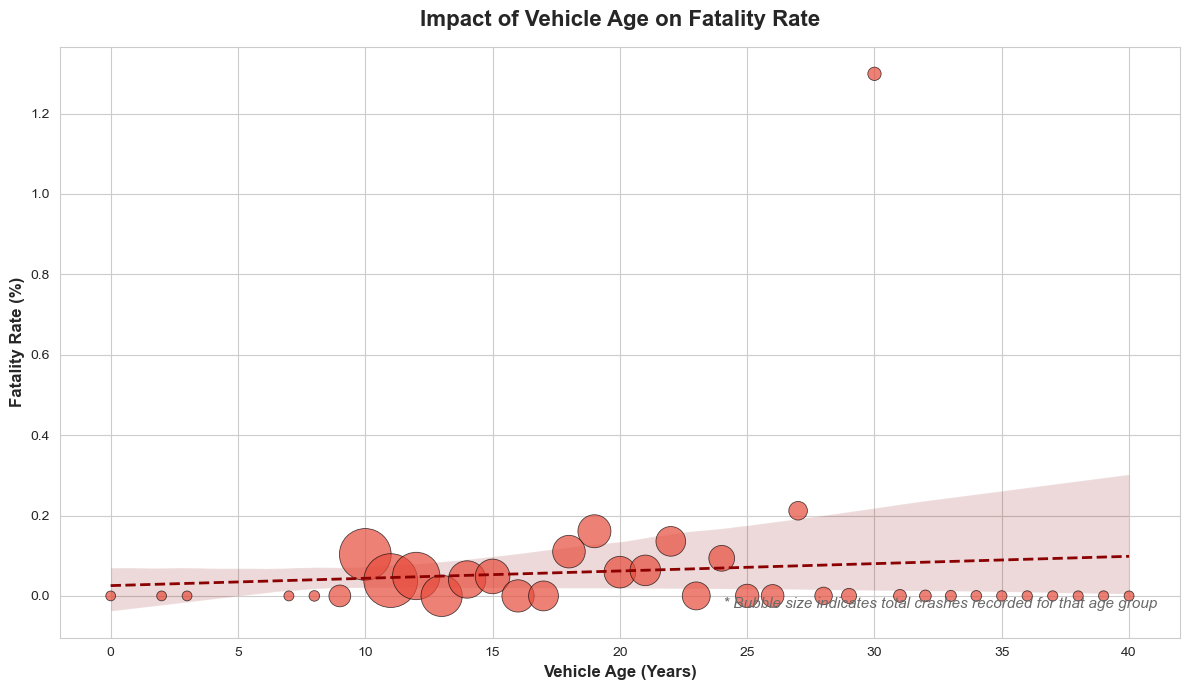

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Data
df = pd.read_csv("Cleaned_Crashes_Time_Categorized.csv", low_memory=False)

# 2. Set the Target
df['FATAL'] = (df['NUMBER OF PERSONS KILLED'] > 0).astype(int)

# 3. Clean Vehicle Age (Filter out data entry errors, restrict to 40 years)
df['VEHICLE_AGE'] = pd.to_numeric(df['VEHICLE_AGE'], errors='coerce')
df_age = df[(df['VEHICLE_AGE'] >= 0) & (df['VEHICLE_AGE'] <= 40)].copy()

# 4. Aggregate Fatality Rate and Total Crashes by exact Vehicle Age
age_stats = df_age.groupby('VEHICLE_AGE').agg(
    FATAL_RATE=('FATAL', 'mean'),
    CRASH_COUNT=('FATAL', 'count')
).reset_index()

# Convert rate to a readable percentage
age_stats['FATAL_RATE_PCT'] = age_stats['FATAL_RATE'] * 100

# 5. Build the Static Plot
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid") # Adds a clean, professional grid background

# Step A: Draw the OLS trendline first so it sits cleanly behind the bubbles
sns.regplot(
    data=age_stats, 
    x='VEHICLE_AGE', 
    y='FATAL_RATE_PCT', 
    scatter=False,  # We only want the line here
    color='darkred',
    line_kws={"linewidth": 2, "linestyle": "--"}
)

# Step B: Draw the Bubble Scatter Plot
sns.scatterplot(
    data=age_stats, 
    x='VEHICLE_AGE', 
    y='FATAL_RATE_PCT', 
    size='CRASH_COUNT', 
    sizes=(50, 1500), # Scales the bubbles appropriately 
    alpha=0.7, 
    color='#e74c3c', 
    edgecolor='black',
    legend=False # Hides the default legend to keep the report clean
)

# 6. Formatting & Labels
plt.title('Impact of Vehicle Age on Fatality Rate', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Vehicle Age (Years)', fontsize=12, fontweight='bold')
plt.ylabel('Fatality Rate (%)', fontsize=12, fontweight='bold')

# Add an annotation explaining the bubble size for static report readers
plt.text(0.98, 0.05, '* Bubble size indicates total crashes recorded for that age group', 
         transform=plt.gca().transAxes, fontsize=11, ha='right', style='italic', color='dimgrey')

plt.tight_layout()

# 7. Save as a high-resolution PNG
plt.savefig('static_vehicle_age_fatality.png', dpi=300, bbox_inches='tight')
plt.show() # Displays the image right below your notebook cell

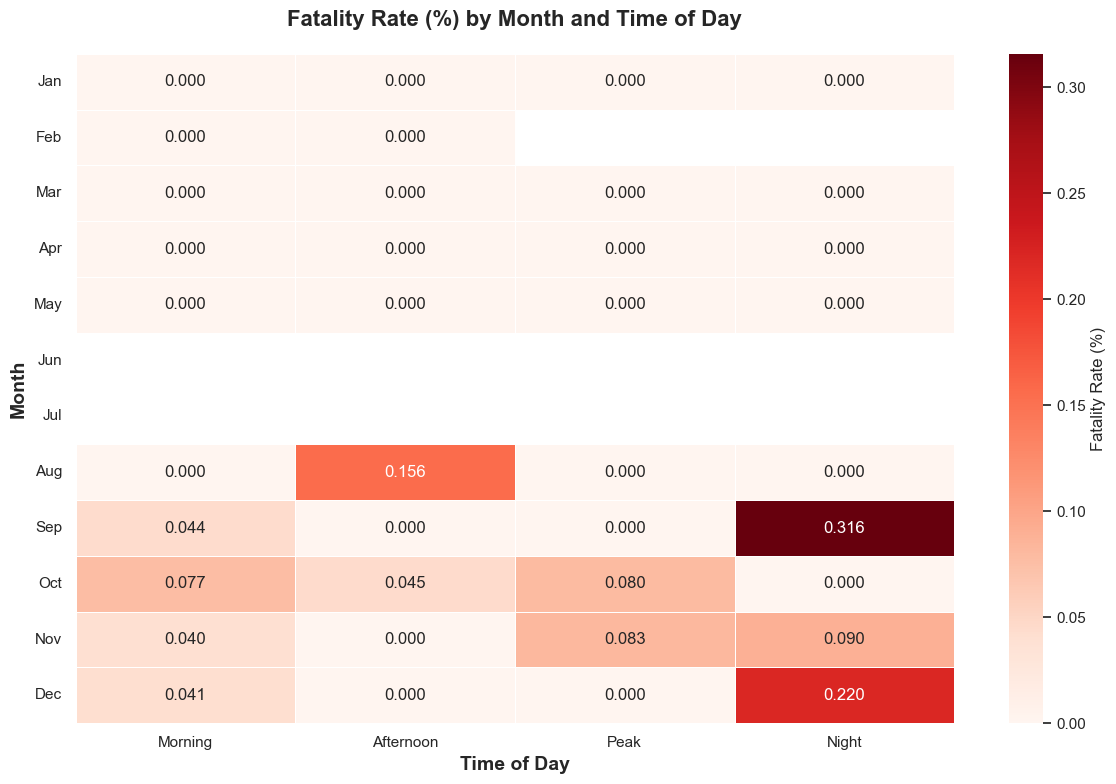

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

# 1. Load Data (Using skiprows=1 to bypass the Excel title row we found earlier!)
df = pd.read_csv("Cleaned_Crashes_Time_Categorized.csv", low_memory=False)

# 2. Set Target Variable
df['FATAL'] = pd.to_numeric(df['NUMBER OF PERSONS KILLED'], errors='coerce').fillna(0)
df['FATAL'] = (df['FATAL'] > 0).astype(int)

# 3. Process Time of Day
df['CRASH_TIME'] = pd.to_datetime(df['CRASH_TIME'], format='%H:%M', errors='coerce')
df['HOUR'] = df['CRASH_TIME'].dt.hour

def get_time_label(h):
    if pd.isna(h): return 'Unknown'
    if 6 <= h < 12: return 'Morning'
    elif 12 <= h < 16: return 'Afternoon'
    elif 16 <= h < 20: return 'Peak'
    else: return 'Night'

df['TIME_OF_DAY'] = df['HOUR'].apply(get_time_label)

# 4. Process Month
df['CRASH_DATE'] = pd.to_datetime(df['CRASH_DATE'], errors='coerce')
df['MONTH_NUM'] = df['CRASH_DATE'].dt.month

# Map month numbers to short names (Jan, Feb, Mar...)
df['MONTH'] = df['MONTH_NUM'].apply(lambda x: calendar.month_abbr[int(x)] if pd.notna(x) else 'Unknown')

# 5. Filter out unknowns and build the matrix
df_clean = df[(df['TIME_OF_DAY'] != 'Unknown') & (df['MONTH'] != 'Unknown')]
heatmap_data = df_clean.groupby(['MONTH', 'TIME_OF_DAY'])['FATAL'].mean().unstack() * 100

# Reorder the rows and columns so they flow chronologically
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
time_order = ['Morning', 'Afternoon', 'Peak', 'Night']
heatmap_data = heatmap_data.reindex(index=month_order, columns=time_order)

# 6. Plot the Static Heatmap
plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

# Create the heatmap
ax = sns.heatmap(
    heatmap_data, 
    annot=True,          # Show the numbers inside the boxes
    fmt=".3f",           # Format to 3 decimal places
    cmap="Reds",         # Darker red = deadlier
    linewidths=.5,       # Add crisp grid lines between boxes
    cbar_kws={'label': 'Fatality Rate (%)'}
)

# Formatting and Labels
plt.title("Fatality Rate (%) by Month and Time of Day", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Time of Day", fontsize=14, fontweight='bold')
plt.ylabel("Month", fontsize=14, fontweight='bold')

# Rotate the x-axis labels slightly for a cleaner look
plt.xticks(rotation=0, fontsize=11)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()

# Save the high-resolution image for your presentation
plt.savefig('heatmap_month_vs_time.png', dpi=300, bbox_inches='tight')

# Display directly in Jupyter
plt.show()